In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
%matplotlib inline

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving income.csv to income.csv


In [ ]:
df = pd.read_csv('income.csv')

In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (22, 3)


In [ ]:
df.isnull().sum()

,0
Name,0
Age,0
Income($),0


In [ ]:
X = df[['Age', 'Income($)']]

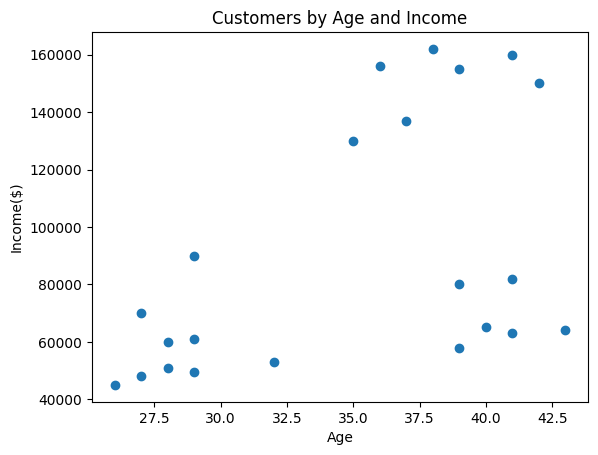

In [ ]:
plt.scatter(X['Age'], X['Income($)'])
plt.xlabel('Age')
plt.ylabel('Income($)')
plt.title('Customers by Age and Income')
plt.show()

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

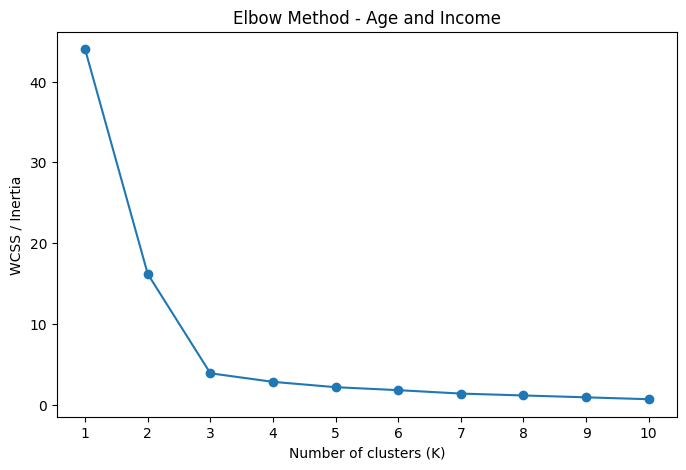

In [ ]:
wcss = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('WCSS / Inertia')
plt.title('Elbow Method - Age and Income')
plt.xticks(range(1, 11))
plt.show()

In [ ]:
chosen_k = 3
model = KMeans(n_clusters=chosen_k, init='k-means++', n_init=10, random_state=42)

In [ ]:
labels = model.fit_predict(X_scaled)
df['Cluster'] = labels

In [ ]:
print("\nFirst 5 rows of the updated DataFrame:")
display(df.head())


First 5 rows of the updated DataFrame:


,Name,Age,Income($),Cluster
0,Rob,27,70000,1
1,Michael,29,90000,1
2,Mohan,29,61000,1
3,Ismail,28,60000,1
4,Kory,42,150000,0


In [ ]:
print("\nCluster Sizes:")
print(df['Cluster'].value_counts().sort_index())


Cluster Sizes:
Cluster
0    7
1    9
2    6
Name: count, dtype: int64


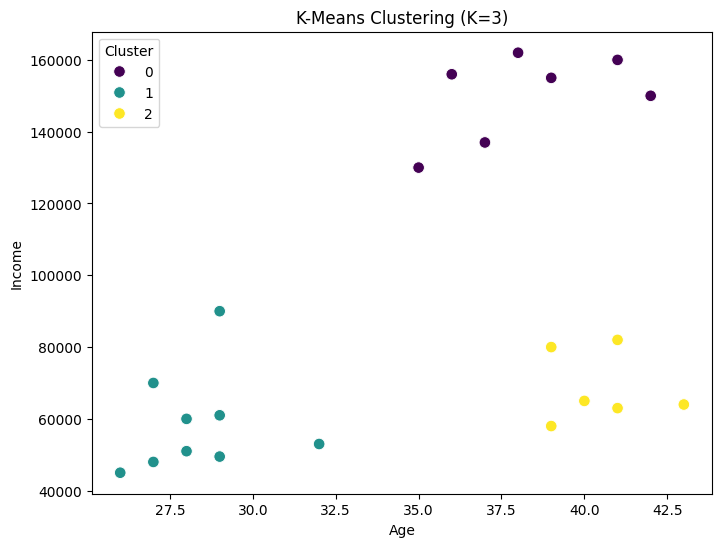

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='Age',
    y='Income($)',
    hue='Cluster',
    data=df,
    palette='viridis',
    s=70
)
plt.title(f'K-Means Clustering (K={chosen_k})')
plt.xlabel('Age')
plt.ylabel('Income')
plt.legend(title='Cluster')
plt.show()